# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chỉ là **khung**: bạn tự viết mã theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

In [1]:
# Clone repo cá nhân (fork) vào Colab và chuyển vào thư mục dự án
import os
REPO = 'https://github.com/taquangdung123/K4-Track-4-Day10-VisionLanguageModel.git'
if not os.path.exists('/content/K4-Track-4-Day10-VisionLanguageModel'):
    !git clone {REPO} /content/K4-Track-4-Day10-VisionLanguageModel
%cd /content/K4-Track-4-Day10-VisionLanguageModel

Cloning into '/content/K4-Track-4-Day10-VisionLanguageModel'...
remote: Enumerating objects: 74, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 74 (delta 13), reused 10 (delta 10), pack-reused 55 (from 1)
Receiving objects: 100% (74/74), 3.11 MiB | 15.68 MiB/s, done.
Resolving deltas: 100% (24/24), done.
/content/K4-Track-4-Day10-VisionLanguageModel


In [2]:
# Runtime → Change runtime type → T4 GPU
!nvidia-smi -L
!pip -q install -r requirements-colab.txt

GPU 0: Tesla T4 (UUID: GPU-656193c9-e7bf-76d2-cf30-f419f0f2434f)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 3.5 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 4.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 889.0/889.0 kB 4.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 2.1 MB/s eta 0:00:0000:0100:01


In [3]:
# Kaggle: dùng Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY). KHÔNG viết khoá vào notebook.
# Không có Secrets (vd. chạy Colab qua VS Code) thì bước 1 tự tải zip public của dataset.
import os
try:
    from google.colab import userdata
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print('Đã nạp Kaggle Secrets')
except Exception as e:
    print('Không đọc được Colab Secrets → sẽ tải zip public:', type(e).__name__)

Không đọc được Colab Secrets → sẽ tải zip public: TimeoutException


In [4]:
# Mount Google Drive để sao lưu adapter LoRA / checkpoint sau mỗi lần chạy
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_DIR = '/content/drive/MyDrive/lab_day10'
except Exception as e:  # vd. Colab qua VS Code: không mount được Drive → sao lưu cục bộ trên máy ảo
    print('Không mount được Drive:', type(e).__name__)
    DRIVE_DIR = '/content/lab_day10_backup'
os.makedirs(DRIVE_DIR, exist_ok=True)
print('Sao lưu vào', DRIVE_DIR)

# Một lần: xoá kết quả E0/E1 chạy với cấu hình cũ (ViT bị lượng tử hoá 4-bit do skip-module 'visual' không khớp)
import shutil
from pathlib import Path
if not Path(DRIVE_DIR, 'VIT_FP16_FIX').exists():
    for f in ['work/e0.jsonl', 'work/e1_test.jsonl', 'report/evidence/e0.json', 'report/evidence/e1.json',
              f'{DRIVE_DIR}/e0.jsonl', f'{DRIVE_DIR}/e1_test.jsonl']:
        Path(f).unlink(missing_ok=True)
    for d in ['work/E1', 'work/E2', f'{DRIVE_DIR}/E1', f'{DRIVE_DIR}/E2']:
        shutil.rmtree(d, ignore_errors=True)
    Path(DRIVE_DIR, 'VIT_FP16_FIX').touch()
    print('Đã xoá kết quả E0/E1 cũ (ViT 4-bit) → sẽ chạy lại')

# Khôi phục output suy luận đã sao lưu trên Drive (sau khi mất session / tắt máy)
Path('work').mkdir(exist_ok=True)
for f in Path(DRIVE_DIR).glob('*.jsonl'):
    if not Path('work', f.name).exists():
        shutil.copy(f, 'work/'); print('Khôi phục', f.name)


Mounted at /content/drive
Sao lưu vào /content/drive/MyDrive/lab_day10
Khôi phục e0.jsonl


In [5]:
# Kiểm tra công cụ của đề: kỳ vọng `68 passed, 1 skipped`
!python -m pytest -q
!python -m pytest rl -q  # test hàm reward E5

...........................s.........................................    [100%]
68 passed, 1 skipped in 0.46s
...........                                                              [100%]
11 passed in 0.03s


## 1. Dữ liệu: tải và chia split

In [6]:
if os.path.exists('data/splits/meta.json'):
    print('Dữ liệu đã có')
elif os.environ.get('KAGGLE_USERNAME') and os.environ.get('KAGGLE_KEY'):
    !python scripts/prepare_data.py --kaggle
else:  # dataset public (MIT): tải zip không cần đăng nhập
    !mkdir -p /content/dl && curl -sL -o /content/dl/road.zip https://www.kaggle.com/api/v1/datasets/download/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes
    !python scripts/prepare_data.py --zip /content/dl/road.zip

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


dataset_version: d10-21e4070301
train  1422 ảnh | 3515 box {'pothole': 1074, 'crack': 1750, 'manhole': 691} | ảnh không box: 0 | 13 session
val     276 ảnh |  639 box {'pothole': 66, 'crack': 470, 'manhole': 103} | ảnh không box: 0 | 2 session
test    311 ảnh |  583 box {'pothole': 121, 'crack': 299, 'manhole': 163} | ảnh không box: 0 | 3 session
OK: không session nào xuất hiện ở hai split


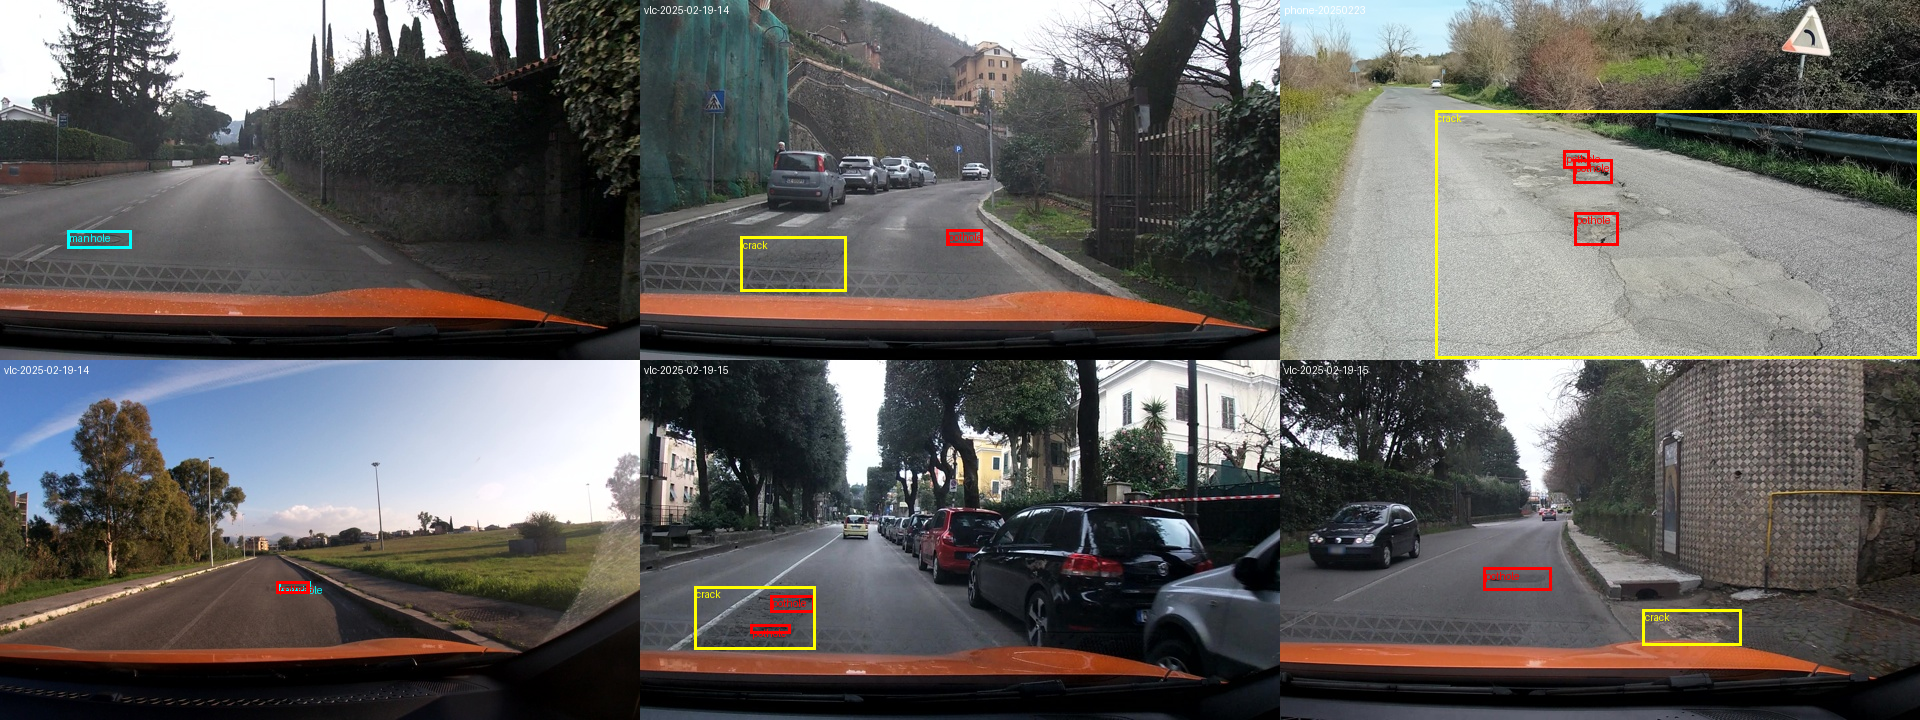

In [7]:
# Bước 1 · Kiểm tra dữ liệu: thống kê từng split, rò rỉ session, vẽ 6 ảnh có box
import json, random
from collections import Counter
from pathlib import Path
from PIL import Image, ImageDraw
from scripts.labcommon import CLASSES, read_jsonl

DATA = Path('data')
splits = {s: read_jsonl(DATA / 'splits' / f'{s}.jsonl') for s in ('train', 'val', 'test')}
meta = json.loads((DATA / 'splits' / 'meta.json').read_text(encoding='utf-8'))
print('dataset_version:', meta['dataset_version'])
assert meta['dataset_version'].startswith('d10-')

for s, rows in splits.items():
    boxes = Counter(o['label'] for r in rows for o in r['objects'])
    n_empty = sum(not r['objects'] for r in rows)
    print(f"{s:5s} {len(rows):5d} ảnh | {sum(boxes.values()):4d} box "
          f"{dict((c, boxes[c]) for c in CLASSES)} | ảnh không box: {n_empty} | "
          f"{len({r['session'] for r in rows})} session")

# Không session nào được nằm ở hai split
sess = {s: {r['session'] for r in rows} for s, rows in splits.items()}
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    overlap = sess[a] & sess[b]
    assert not overlap, f'Rò rỉ session {a}/{b}: {overlap}'
print('OK: không session nào xuất hiện ở hai split')

# Vẽ 6 ảnh train có box (nhãn YOLO chuẩn hoá [0,1] → pixel)
COLORS = {'pothole': 'red', 'crack': 'yellow', 'manhole': 'cyan'}
def draw(row):
    img = Image.open(DATA / row['image_path']).convert('RGB')
    W, H = img.size
    d = ImageDraw.Draw(img)
    for o in row['objects']:
        xc, yc, w, h = o['yolo']
        box = ((xc - w/2) * W, (yc - h/2) * H, (xc + w/2) * W, (yc + h/2) * H)
        d.rectangle(box, outline=COLORS[o['label']], width=3)
        d.text((box[0] + 2, box[1] + 2), o['label'], fill=COLORS[o['label']])
    d.text((4, 4), row['session'], fill='white')
    return img

random.seed(0)
samples = random.sample([r for r in splits['train'] if r['objects']], 6)
tiles = [draw(r) for r in samples]
W, H = tiles[0].size
grid = Image.new('RGB', (W * 3, H * 2))
for i, t in enumerate(tiles):
    grid.paste(t, ((i % 3) * W, (i // 3) * H))
Path('report/figures').mkdir(parents=True, exist_ok=True)
grid.save('report/figures/step1_train_samples.jpg', quality=85)
grid

## 2. Nhãn: YOLO → JSON thang 0–1000

20250216_164325 → [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]
Sai số lớn nhất khi quy ngược về pixel trên toàn train: 0.32px


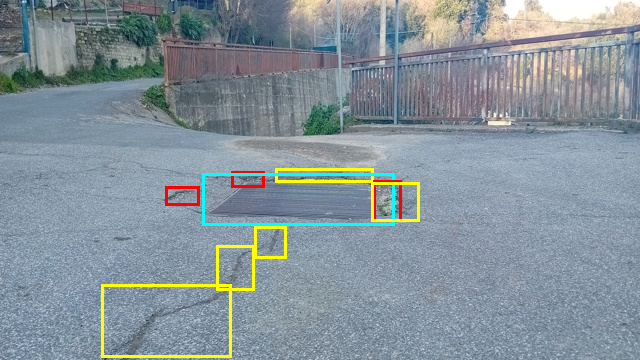

In [8]:
# Bước 2 · Nhãn YOLO → JSON thang 0–1000, prompt, và kiểm tra quy đổi ngược về pixel
import json

def yolo_to_box(label, yolo):
    xc, yc, w, h = yolo  # chuẩn hoá [0, 1], tâm + kích thước
    clamp = lambda v: int(round(max(0.0, min(1000.0, v * 1000))))
    x1, y1 = clamp(xc - w / 2), clamp(yc - h / 2)
    x2, y2 = clamp(xc + w / 2), clamp(yc + h / 2)
    if x2 <= x1: x2 = min(1000, x1 + 1)
    if y2 <= y1: y2 = min(1000, y1 + 1)
    return {"label": label, "bbox_2d": [x1, y1, x2, y2]}

def objects_to_answer(objects, row=None):  # row: dùng cho biến thể pixel ở E4
    boxes = [yolo_to_box(o["label"], o["yolo"]) for o in objects]
    boxes.sort(key=lambda b: (b["bbox_2d"][1], b["bbox_2d"][0]))  # trên→dưới, trái→phải
    return json.dumps(boxes, separators=(",", ":"))

PROMPT = (
    "Locate road damage in this image. "
    "Detect only objects of classes: pothole, crack, manhole. "
    "Output a JSON list of objects with label and bbox_2d coordinates "
    "normalized on a 0-1000 scale: "
    '[{"label": "...", "bbox_2d": [x1, y1, x2, y2]}]. '
    "If no damage is found, output []."
)

# Kiểm tra: JSON 0–1000 → pixel phải trùng box gốc (sai số làm tròn ≤ 1 phần nghìn ≈ 0.64px)
row = splits['train'][0]
ans = objects_to_answer(row['objects'])
print(row['image_id'], '→', ans)
W, H = row['width'], row['height']
max_err = 0.0
for r in splits['train']:
    for o in r['objects']:
        xc, yc, w, h = o['yolo']
        gt = [(xc - w/2) * W, (yc - h/2) * H, (xc + w/2) * W, (yc + h/2) * H]
        gt = [min(max(v, 0), lim) for v, lim in zip(gt, (W, H, W, H))]
        b = yolo_to_box(o['label'], o['yolo'])['bbox_2d']
        px = [b[0] / 1000 * W, b[1] / 1000 * H, b[2] / 1000 * W, b[3] / 1000 * H]
        max_err = max(max_err, *(abs(a - g) for a, g in zip(px, gt)))
print(f'Sai số lớn nhất khi quy ngược về pixel trên toàn train: {max_err:.2f}px')
assert max_err < 1.0

# Vẽ lại ảnh từ JSON 0–1000: phải trùng ảnh vẽ từ nhãn YOLO ở bước 1
img = Image.open(DATA / row['image_path']).convert('RGB')
d = ImageDraw.Draw(img)
for b in json.loads(ans):
    x1, y1, x2, y2 = b['bbox_2d']
    d.rectangle((x1/1000*W, y1/1000*H, x2/1000*W, y2/1000*H), outline=COLORS[b['label']], width=3)
img

## 3. E0: zero-shot

In [9]:
# Bước 3 · E0 zero-shot: nạp Qwen3-VL-4B 4-bit (ViT + lm_head giữ fp16), suy luận test → work/e0.jsonl
import os, time, torch
from transformers import AutoProcessor, BitsAndBytesConfig, Qwen3VLForConditionalGeneration
from scripts.labcommon import write_jsonl

MODEL_ID = 'Qwen/Qwen3-VL-4B-Instruct'

def load_base_model():
    quantization = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type='nf4',
        bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True,
        llm_int8_skip_modules=['model.visual', 'lm_head'])  # ViT (kể cả projector) và lm_head không lượng tử hoá
    # transformers 5.x khớp skip-module bằng re.match từ ĐẦU tên: 'visual' không khớp 'model.visual.…' → ViT bị 4-bit
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID, quantization_config=quantization, dtype=torch.float16, device_map={'': 0})
    n_4bit = sum(1 for n, m in model.named_modules() if 'visual' in n and type(m).__name__ == 'Linear4bit')
    assert n_4bit == 0, f'{n_4bit} lớp Linear của ViT/projector bị lượng tử hoá 4-bit'
    processor = AutoProcessor.from_pretrained(MODEL_ID)
    processor.tokenizer.padding_side = 'left'  # bắt buộc khi generate theo batch
    return model, processor

def user_message(img, prompt=None):
    return {'role': 'user', 'content': [{'type': 'image', 'image': img}, {'type': 'text', 'text': prompt or PROMPT}]}

@torch.no_grad()
def run_inference(model, processor, rows, out_path, batch_size=4, max_new_tokens=256, prompt=None):
    """Suy luận và ghi {"image_id", "raw"} từng dòng. Chạy lại sẽ tiếp tục từ chỗ dừng."""
    out_path = Path(out_path)
    done = {r['image_id'] for r in read_jsonl(out_path)} if out_path.exists() else set()
    todo = [r for r in rows if r['image_id'] not in done]
    model.eval()
    t0 = time.time()
    out_path.parent.mkdir(parents=True, exist_ok=True)
    with open(out_path, 'a', encoding='utf-8') as f:
        for i in range(0, len(todo), batch_size):
            batch = todo[i:i + batch_size]
            convs = [[user_message(Image.open(DATA / r['image_path']).convert('RGB'), prompt)] for r in batch]
            inputs = processor.apply_chat_template(
                convs, tokenize=True, add_generation_prompt=True,
                return_dict=True, return_tensors='pt', padding=True).to(model.device)
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
            raws = processor.batch_decode(out[:, inputs['input_ids'].shape[1]:], skip_special_tokens=True)
            for r, raw in zip(batch, raws):
                f.write(json.dumps({'image_id': r['image_id'], 'raw': raw}, ensure_ascii=False) + '\n')
            f.flush()
            print(f'\r{len(done) + i + len(batch)}/{len(rows)} ảnh, {time.time() - t0:.0f}s', end='')
    print()

model, processor = load_base_model()
print(f'VRAM sau khi nạp: {torch.cuda.memory_allocated() / 1e9:.2f} GB')
run_inference(model, processor, splits['test'], 'work/e0.jsonl')
del model; import gc; gc.collect(); torch.cuda.empty_cache()  # giải phóng VRAM trước khi train

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

VRAM sau khi nạp: 3.51 GB



In [10]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json
!cp work/e0.jsonl {DRIVE_DIR}/  # sao lưu output thô lên Drive

E0 [test] n=311 valid=0.836 P=0.120 R=0.067 F1=0.086 CI95=0.061-0.113 meanIoU=0.601 FP/img=0.92
   pothole  P=0.286 R=0.066 F1=0.107
   crack    P=0.040 R=0.027 F1=0.032
   manhole  P=0.240 R=0.141 F1=0.178


In [11]:
# Xem output thô của E0 để trả lời Câu 2: model trả gì, lỗi phổ biến nào?
from scripts.score import parse_output
e0 = read_jsonl('work/e0.jsonl')
bad = [r for r in e0 if parse_output(r['raw']) is None]
print(f'parse_valid_rate = {1 - len(bad) / len(e0):.3f}  ({len(bad)} output hỏng)')
print(f"Bọc ```json: {sum('```' in r['raw'] for r in e0)} · output rỗng []: {sum(r['raw'].strip() == '[]' for r in e0)}")
for r in e0[:5] + bad[:3]:
    print('---', r['image_id']); print(r['raw'][:400])

parse_valid_rate = 0.836  (51 output hỏng)
Bọc ```json: 0 · output rỗng []: 17
--- vlcsnap-00200
[{"label": "manhole", "bbox_2d": [770, 640, 843, 686]}, {"label": "manhole", "bbox_2d": [909, 786, 998, 822]}]
--- vlcsnap-00201
[]
--- vlcsnap-00202
[{"label": "manhole", "bbox_2d": [309, 686, 399, 714]}]
--- vlcsnap-00203
[]
--- vlcsnap-00204
[{"label": "manhole", "bbox_2d": [257, 627, 325, 657]}]
--- vlcsnap-2025-02-18-23h07m47s847
[{"label": "crack", "bbox_2d": [350, 370, 400, 400]}, {"label": "crack", "bbox_2d": [350, 330, 400, 360]}, {"label": "crack", "bbox_2d": [350, 290, 400, 320]}, {"label": "crack", "bbox_2d": [350, 250, 400, 280]}, {"label": "crack", "bbox_2d": [350, 210, 400, 240]}, {"label": "crack", "bbox_2d": [350, 170, 400, 200]}, {"label": "crack", "bbox_2d": [350, 130, 400, 160]}, {"label": "crack", "bbox_2d"
--- vlcsnap-2025-02-18-23h07m53s515
[{"label": "crack", "bbox_2d": [500, 350, 520, 360]}, {"label": "crack", "bbox_2d": [520, 350, 540, 360]}, {"label": "crack", "bb

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [12]:
# Bước 4 · Ví dụ huấn luyện: chat template + mask loss (chỉ học phần trả lời), và collate
import torch

def encode_example(image, prompt, answer, processor):
    user_msg = [{'role': 'user', 'content': [{'type': 'image', 'image': image}, {'type': 'text', 'text': prompt}]}]
    full_msg = user_msg + [{'role': 'assistant', 'content': [{'type': 'text', 'text': answer}]}]
    kw = dict(tokenize=True, return_dict=True, return_tensors='pt')
    prompt_enc = processor.apply_chat_template(user_msg, add_generation_prompt=True, **kw)
    full_enc = processor.apply_chat_template(full_msg, add_generation_prompt=False, **kw)
    n = prompt_enc['input_ids'].shape[1]
    # prompt (kể cả token ảnh và "<|im_start|>assistant\n") phải là tiền tố của chuỗi đầy đủ
    assert torch.equal(full_enc['input_ids'][0, :n], prompt_enc['input_ids'][0])
    labels = full_enc['input_ids'].clone()
    labels[:, :n] = -100  # không tính loss trên ảnh + prompt
    ex = {k: v[0] for k, v in full_enc.items() if k not in ('pixel_values', 'image_grid_thw')}
    ex.update(pixel_values=full_enc['pixel_values'], image_grid_thw=full_enc['image_grid_thw'], labels=labels[0])
    return ex

def collate(batch, pad_token_id):
    pad = lambda key, value: torch.nn.utils.rnn.pad_sequence([b[key] for b in batch], batch_first=True, padding_value=value)
    out = {'input_ids': pad('input_ids', pad_token_id), 'attention_mask': pad('attention_mask', 0), 'labels': pad('labels', -100)}
    if 'mm_token_type_ids' in batch[0]:
        out['mm_token_type_ids'] = pad('mm_token_type_ids', 0)
    # tensor ảnh: nối theo chiều 0, KHÔNG pad
    out['pixel_values'] = torch.cat([b['pixel_values'] for b in batch], dim=0)
    out['image_grid_thw'] = torch.cat([b['image_grid_thw'] for b in batch], dim=0)
    return out

class TrainSet(torch.utils.data.Dataset):
    def __init__(self, rows, processor, prompt=None, answer_fn=None):
        self.rows, self.processor = rows, processor
        self.prompt, self.answer_fn = prompt or PROMPT, answer_fn or objects_to_answer
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        r = self.rows[i]
        img = Image.open(DATA / r['image_path']).convert('RGB')
        return encode_example(img, self.prompt, self.answer_fn(r['objects'], r), self.processor)

# Kiểm tra trên một ví dụ
proc = AutoProcessor.from_pretrained(MODEL_ID)
r = splits['train'][0]
ex = encode_example(Image.open(DATA / r['image_path']).convert('RGB'), PROMPT, objects_to_answer(r['objects']), proc)
image_token_id = proc.tokenizer.convert_tokens_to_ids('<|image_pad|>')
merge = proc.image_processor.merge_size
print('image_grid_thw:', ex['image_grid_thw'].tolist(), '→', int(ex['image_grid_thw'].prod()) // merge**2, 'token ảnh theo grid')
print('Số token <|image_pad|> trong input_ids:', int((ex['input_ids'] == image_token_id).sum()))
assert int((ex['input_ids'] == image_token_id).sum()) == 220
n_ans = int((ex['labels'] != -100).sum())
print(f"Độ dài chuỗi: {len(ex['input_ids'])} token, trong đó {n_ans} token tính loss ({n_ans / len(ex['input_ids']):.1%})")
decoded = proc.tokenizer.decode(ex['labels'][ex['labels'] != -100])
print('Phần tính loss:', repr(decoded))
assert decoded.startswith(objects_to_answer(r['objects'])) and '<|im_end|>' in decoded

b = collate([ex, encode_example(Image.open(DATA / splits['train'][1]['image_path']).convert('RGB'), PROMPT,
                                objects_to_answer(splits['train'][1]['objects']), proc)], proc.tokenizer.pad_token_id)
print({k: tuple(v.shape) for k, v in b.items()})

image_grid_thw: [[1, 22, 40]] → 220 token ảnh theo grid
Số token <|image_pad|> trong input_ids: 220
Độ dài chuỗi: 562 token, trong đó 250 token tính loss (44.5%)
Phần tính loss: '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>\n'
{'input_ids': (2, 562), 'attention_mask': (2, 562), 'labels': (2, 562), 'mm_token_type_ids': (2, 562), 'pixel_values': (1760, 1536), 'image_grid_thw': (2, 3)}


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [13]:
# Bước 5 · Setup LoRA / đóng băng cho E1, E2, E3
import re
from peft import LoraConfig, get_peft_model
import peft.tuners.lora.model as _lora_model

# Colab cài sẵn torchao bản cũ → peft ném ImportError khi dò dispatcher cho nn.Linear thường (ViT ở E3).
# Lớp 4-bit của LLM (E1/E2) được bnb nhận trước nên không gặp. Bỏ qua dispatcher tuỳ chọn bị lỗi import.
def _safe_dispatch(f):
    if getattr(f, '_safe', False):
        return f
    def g(*args, **kwargs):
        try:
            return f(*args, **kwargs)
        except ImportError:
            return None
    g._safe = True
    return g

for _n in ('dispatch_eetq', 'dispatch_aqlm', 'dispatch_awq', 'dispatch_gptq', 'dispatch_hqq', 'dispatch_inc',
           'dispatch_torchao', 'dispatch_megatron', 'dispatch_transformer_engine'):
    setattr(_lora_model, _n, _safe_dispatch(getattr(_lora_model, _n)))

LLM_TARGETS = r'model\.language_model\.layers\.\d+\.(self_attn\.(q|k|v|o)_proj|mlp\.(gate|up|down)_proj)'  # 36 × 7 = 252
VIT_TARGETS = r'model\.visual\.blocks\.\d+\.(attn\.(qkv|proj)|mlp\.linear_fc(1|2))'                        # 24 × 4 = 96
# Không dùng target_modules=["qkv","linear_fc1",...] theo tên đuôi: "linear_fc1/2" khớp cả visual.merger
# và deepstack_merger_list (LoRA sẽ chồng lên projector), còn "proj" thì khớp quá rộng.
PROJECTOR_KEYS = ('visual.merger', 'visual.deepstack_merger_list')

SETUPS = {  # theo configs/e1–e3.yaml
    'E1': dict(vit_lora=False, train_projector=False),
    'E2': dict(vit_lora=False, train_projector=True),
    'E3': dict(vit_lora=True,  train_projector=True),
}

def apply_setup(model, setup, r=16, alpha=32, dropout=0.05):
    cfg = SETUPS[setup]
    for p in model.parameters():
        p.requires_grad = False
    model.enable_input_require_grads()  # cần cho gradient checkpointing khi đầu vào bị đóng băng
    target = f'^({LLM_TARGETS}|{VIT_TARGETS})$' if cfg['vit_lora'] else f'^{LLM_TARGETS}$'
    matched = [n for n, _ in model.named_modules() if re.fullmatch(target, n)]
    model = get_peft_model(model, LoraConfig(r=r, lora_alpha=alpha, lora_dropout=dropout,
                                             target_modules=target, bias='none', task_type='CAUSAL_LM'))
    for p in model.parameters():
        if p.requires_grad:
            p.data = p.data.float()  # LoRA ở fp32: GradScaler không unscale được gradient fp16
    if cfg['train_projector']:
        for n, p in model.named_parameters():
            if any(k in n for k in PROJECTOR_KEYS):
                p.data = p.data.float()  # fp32: AdamW + GradScaler cập nhật ổn định, không tràn/mất số như fp16
                p.requires_grad = True
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'{setup}: {len(matched)} module LoRA, {trainable:,} tham số huấn luyện')
    return model, matched, trainable

def projector_state(model):
    """Tham số projector đã huấn luyện — KHÔNG nằm trong adapter peft, phải lưu riêng."""
    return {n: p.detach().cpu() for n, p in model.named_parameters() if any(k in n for k in PROJECTOR_KEYS) and p.requires_grad}

## 6. Vòng huấn luyện

In [14]:
# Bước 6 · Vòng huấn luyện: AdamW + warmup 5% + cosine, fp16 autocast + GradScaler, tích luỹ gradient
import gc, math, random, shutil
from transformers import get_cosine_schedule_with_warmup

def free_gpu():
    gc.collect(); torch.cuda.empty_cache()

def save_checkpoint(model, out_dir):
    out_dir = Path(out_dir)
    model.save_pretrained(out_dir / 'adapter')                # peft: CHỈ lưu adapter LoRA
    proj = projector_state(model)
    if proj:                                                   # E2/E3: projector huấn luyện đầy đủ, lưu riêng
        torch.save(proj, out_dir / 'projector.pt')

def train(name, setup, max_steps=300, lr=2e-4, batch_size=2, grad_accum=4, r=16, alpha=32,
          train_rows=None, prompt=None, answer_fn=None, seed=42, log_every=10, save_every=100):
    out_dir = Path('work') / name
    out_dir.mkdir(parents=True, exist_ok=True)
    random.seed(seed); torch.manual_seed(seed)
    model, processor = load_base_model()
    model, matched, trainable = apply_setup(model, setup, r=r, alpha=alpha)
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})
    model.config.use_cache = False
    model.train()

    rows = train_rows if train_rows is not None else splits['train']
    loader = torch.utils.data.DataLoader(
        TrainSet(rows, processor, prompt, answer_fn), batch_size=batch_size, shuffle=True, num_workers=2,
        generator=torch.Generator().manual_seed(seed),
        collate_fn=lambda b: collate(b, processor.tokenizer.pad_token_id))
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    sched = get_cosine_schedule_with_warmup(opt, math.ceil(0.05 * max_steps), max_steps)
    scaler = torch.amp.GradScaler('cuda')

    torch.cuda.reset_peak_memory_stats()
    t0, step, log, it = time.time(), 0, [], iter(loader)
    while step < max_steps:
        step_loss = 0.0
        for _ in range(grad_accum):
            try:
                batch = next(it)
            except StopIteration:  # hết một epoch → xáo lại
                it = iter(loader); batch = next(it)
            batch = {k: v.to(model.device) for k, v in batch.items()}
            with torch.autocast('cuda', dtype=torch.float16):
                loss = model(**batch).loss / grad_accum
            if not torch.isfinite(loss):
                raise RuntimeError(f'Loss không hữu hạn ở bước {step}: {loss.item()} (tràn số fp16?)')
            scaler.scale(loss).backward()
            step_loss += loss.item()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
        step += 1
        log.append(step_loss)
        if step % log_every == 0:
            print(f'[{name}] bước {step}/{max_steps} loss={sum(log[-log_every:]) / log_every:.4f} '
                  f'lr={sched.get_last_lr()[0]:.2e} {(time.time() - t0) / 60:.1f} phút')
        if step % save_every == 0 or step == max_steps:
            save_checkpoint(model, out_dir)

    run = {'name': name, 'setup': setup, 'lora_modules': len(matched), 'trainable_params': trainable,
           'peak_vram_gb': round(torch.cuda.max_memory_allocated() / 1e9, 2),
           'train_minutes': round((time.time() - t0) / 60, 1), 'max_steps': max_steps, 'r': r, 'alpha': alpha,
           'train_images': len(rows), 'coord': 'pixel' if answer_fn else 'norm1000', 'loss': log}
    (out_dir / 'run.json').write_text(json.dumps(run, indent=1), encoding='utf-8')
    shutil.copytree(out_dir, f'{DRIVE_DIR}/{name}', dirs_exist_ok=True)  # Colab free có thể ngắt
    print({k: v for k, v in run.items() if k != 'loss'})
    del model, opt, scaler; free_gpu()
    return run

## 7. Suy luận và chấm E1–E3

In [15]:
# Bước 7 · Suy luận và chấm: nạp model gốc → adapter LoRA → projector đã huấn luyện (E2/E3)
import subprocess
from peft import PeftModel

def load_finetuned(name, trainable=False):
    out_dir = Path('work') / name
    model, processor = load_base_model()
    model = PeftModel.from_pretrained(model, out_dir / 'adapter', is_trainable=trainable)
    proj_path = out_dir / 'projector.pt'
    if proj_path.exists():  # quên bước này thì E2/E3 sẽ dùng projector gốc → trông giống E1
        proj = torch.load(proj_path)
        missing = set(proj) - {n for n, _ in model.named_parameters()}
        assert not missing, f'Tên projector không khớp: {list(missing)[:3]}'
        model.load_state_dict(proj, strict=False)
        print(f'Đã nạp lại {len(proj)} tensor projector')
    return model, processor

def evaluate_run(name, evidence_name=None, split='test', coord='norm1000', prompt=None):
    model, processor = load_finetuned(name)
    rows = splits[split]
    pred = f'work/{name.lower()}_{split}.jsonl'
    run_inference(model, processor, rows, pred, prompt=prompt)
    del model; free_gpu()
    run = json.loads((Path('work') / name / 'run.json').read_text(encoding='utf-8'))
    evidence = evidence_name or name.lower()
    out = f'report/evidence/{evidence}.json' if split == 'test' else f'work/{evidence}_{split}_score.json'
    cmd = ['python', 'scripts/score.py', '--pred', pred, '--name', name, '--split', split, '--coord', coord,
           '--out', out] + sum([['--meta', f'{k}={run[k]}'] for k in ('trainable_params', 'peak_vram_gb', 'train_minutes')], [])
    print(subprocess.run(cmd, capture_output=True, text=True).stdout)
    shutil.copy(pred, DRIVE_DIR)

# Chạy lần lượt (mỗi setup ≈ 20–35 phút train + vài phút suy luận). Có thể tách ra nhiều session Colab.
for name in ['E1', 'E2', 'E3']:
    if not (Path('work') / name).exists() and Path(f'{DRIVE_DIR}/{name}/run.json').exists():
        shutil.copytree(f'{DRIVE_DIR}/{name}', Path('work') / name)  # khôi phục sau khi mất session
    if not (Path('work') / name / 'run.json').exists():
        train(name, name)
    evaluate_run(name)

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

E1: 252 module LoRA, 33,030,144 tham số huấn luyện


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


[E1] bước 10/300 loss=1.3124 lr=1.33e-04 1.4 phút
[E1] bước 20/300 loss=0.7829 lr=2.00e-04 2.8 phút
[E1] bước 30/300 loss=0.7038 lr=1.99e-04 4.2 phút
[E1] bước 40/300 loss=0.6548 lr=1.96e-04 5.6 phút
[E1] bước 50/300 loss=0.6350 lr=1.93e-04 6.9 phút
[E1] bước 60/300 loss=0.6331 lr=1.88e-04 8.3 phút
[E1] bước 70/300 loss=0.6412 lr=1.82e-04 9.7 phút
[E1] bước 80/300 loss=0.6437 lr=1.75e-04 11.1 phút
[E1] bước 90/300 loss=0.6108 lr=1.68e-04 12.5 phút
[E1] bước 100/300 loss=0.6283 lr=1.59e-04 13.9 phút
[E1] bước 110/300 loss=0.6169 lr=1.50e-04 15.3 phút
[E1] bước 120/300 loss=0.6047 lr=1.40e-04 16.7 phút
[E1] bước 130/300 loss=0.5760 lr=1.30e-04 18.1 phút
[E1] bước 140/300 loss=0.6157 lr=1.19e-04 19.5 phút
[E1] bước 150/300 loss=0.6013 lr=1.08e-04 20.9 phút
[E1] bước 160/300 loss=0.6115 lr=9.72e-05 22.3 phút
[E1] bước 170/300 loss=0.6100 lr=8.63e-05 23.6 phút
[E1] bước 180/300 loss=0.6000 lr=7.55e-05 25.0 phút
[E1] bước 190/300 loss=0.5872 lr=6.49e-05 26.4 phút
[E1] bước 200/300 loss=0.585

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

...

304/311 ảnh, 969s

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


311/311 ảnh, 984s
E2 [test] n=311 valid=1.000 P=0.325 R=0.304 F1=0.314 CI95=0.277-0.352 meanIoU=0.676 FP/img=1.18
   pothole  P=0.186 R=0.174 F1=0.179
   crack    P=0.248 R=0.271 F1=0.259
   manhole  P=0.708 R=0.460 F1=0.558



Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

ImportError: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported

In [ ]:
# Ảnh minh hoạ: 3 ảnh dự đoán tốt nhất và 3 ảnh tệ nhất của setup tốt nhất (xanh lá = GT, đỏ = dự đoán)
from scripts.score import parse_output
from rl.reward import compute_reward
from PIL import ImageFont

best = max(('E1', 'E2', 'E3'), key=lambda n: json.loads(Path(f'report/evidence/{n.lower()}.json').read_text(encoding='utf-8'))['micro']['f1'])
by_id = {r['image_id']: r for r in splits['test']}
preds = {r['image_id']: r['raw'] for r in read_jsonl(f'work/{best.lower()}_test.jsonl')}
scored = sorted(((compute_reward(raw, parse_output(objects_to_answer(by_id[i]['objects']))), i) for i, raw in preds.items()), reverse=True)
picks = [('ĐÚNG', s, i) for s, i in scored[:3]] + [('SAI', s, i) for s, i in scored[-3:]]

def draw_pred(image_id, tag, score):
    r = by_id[image_id]
    img = Image.open(DATA / r['image_path']).convert('RGB'); W, H = img.size; d = ImageDraw.Draw(img)
    for b in json.loads(objects_to_answer(r['objects'])):
        x1, y1, x2, y2 = b['bbox_2d']; d.rectangle((x1*W/1000, y1*H/1000, x2*W/1000, y2*H/1000), outline='lime', width=3)
        d.text((x1*W/1000 + 2, y2*H/1000 + 2), b['label'], fill='lime')
    for b in parse_output(preds[image_id]) or []:
        x1, y1, x2, y2 = b['bbox']; d.rectangle((x1*W/1000, y1*H/1000, x2*W/1000, y2*H/1000), outline='red', width=2)
        d.text((x1*W/1000 + 2, y1*H/1000 + 2), b['label'], fill='red')
    d.rectangle((0, 0, W, 16), fill='black')
    d.text((4, 2), f'{best} {tag} reward={score:.2f} {image_id}', fill='white')
    return img

tiles = [draw_pred(i, tag, s) for tag, s, i in picks]
W, H = tiles[0].size
grid = Image.new('RGB', (W * 3, H * 2))
for k, t in enumerate(tiles):
    grid.paste(t, ((k % 3) * W, (k // 3) * H))
grid.save('report/figures/predictions_best_worst.jpg', quality=85)
for tag, s, i in picks:
    print(tag, i, f'reward={s:.2f}', '| GT:', objects_to_answer(by_id[i]['objects'])[:150], '| PRED:', preds[i][:150])
grid

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [ ]:
# Bước 8 · E4: ablation đổi ĐÚNG MỘT biến so với setup tốt nhất trong E1–E3
ABLATION = 'data_size'  # 'data_size' | 'rank' | 'coord_scale'

ev = {n: json.loads(Path(f'report/evidence/{n.lower()}.json').read_text(encoding='utf-8')) for n in ('E1', 'E2', 'E3')}
BEST = max(ev, key=lambda n: ev[n]['micro']['f1'])
print('Setup gốc cho E4:', BEST, {n: round(e['micro']['f1'], 4) for n, e in ev.items()})

def objects_to_answer_pixel(objects, row):
    """Biến thể coord_scale=pixel: cùng box, nhưng toạ độ là pixel tuyệt đối của ảnh."""
    W, H = row['width'], row['height']
    boxes = json.loads(objects_to_answer(objects))
    for b in boxes:
        x1, y1, x2, y2 = b['bbox_2d']
        b['bbox_2d'] = [round(x1 * W / 1000), round(y1 * H / 1000), round(x2 * W / 1000), round(y2 * H / 1000)]
    return json.dumps(boxes, separators=(',', ':'))

PROMPT_PIXEL = PROMPT.replace('normalized on a 0-1000 scale', 'in absolute pixel coordinates of the 640x360 image')
assert PROMPT_PIXEL != PROMPT

# Mỗi biến thể: (tên evidence, tham số train, tham số chấm). Giá trị trùng setup gốc thì dùng lại run gốc.
if ABLATION == 'data_size':
    rows10 = random.Random(42).sample(splits['train'], round(0.1 * len(splits['train'])))
    variants = [('e4_data_0.1', dict(train_rows=rows10), {}),
                ('e4_data_1.0', None, {})]                       # 100% train = chính setup gốc
elif ABLATION == 'rank':
    variants = [('e4_rank_4', dict(r=4, alpha=8), {}),
                ('e4_rank_64', dict(r=64, alpha=128), {})]       # gốc là r=16, nên chạy cả hai
else:
    variants = [('e4_coord_norm1000', None, {}),
                ('e4_coord_pixel', dict(prompt=PROMPT_PIXEL, answer_fn=objects_to_answer_pixel),
                 dict(coord='pixel', prompt=PROMPT_PIXEL))]

for evidence, train_kw, eval_kw in variants:
    if train_kw is None:  # trùng setup gốc: chấm lại từ dự đoán đã có, gắn tên E4
        pred = f'work/{BEST.lower()}_test.jsonl'
        run = json.loads((Path('work') / BEST / 'run.json').read_text(encoding='utf-8'))
        cmd = ['python', 'scripts/score.py', '--pred', pred, '--name', evidence.upper(), '--out', f'report/evidence/{evidence}.json']
        cmd += sum([['--meta', f'{k}={run[k]}'] for k in ('trainable_params', 'peak_vram_gb', 'train_minutes')], [])
        print(subprocess.run(cmd, capture_output=True, text=True).stdout)
        continue
    name = evidence.upper()
    if not (Path('work') / name).exists() and Path(f'{DRIVE_DIR}/{name}/run.json').exists():
        shutil.copytree(f'{DRIVE_DIR}/{name}', Path('work') / name)
    if not (Path('work') / name / 'run.json').exists():
        train(name, BEST, **train_kw)
    evaluate_run(name, evidence_name=evidence, **eval_kw)

# So sánh hai giá trị: CI95 có giao nhau không?
res = {e: json.loads(Path(f'report/evidence/{e}.json').read_text(encoding='utf-8')) for e, _, _ in variants}
for e, d in res.items():
    print(f"{e:20s} F1={d['micro']['f1']:.4f} CI95={[round(x, 4) for x in d['f1_ci95']]} FP/ảnh={d['fp_per_image']:.2f}")
(a, da), (b, db) = res.items()
overlap = da['f1_ci95'][0] <= db['f1_ci95'][1] and db['f1_ci95'][0] <= da['f1_ci95'][1]
print('CI95 giao nhau → chưa đủ bằng chứng khác biệt' if overlap else 'CI95 tách rời → khác biệt rõ ràng')

### E5 (tuỳ chọn, +10): GRPO với reward IoU
Hàm reward và test nằm ở `rl/` (`python -m pytest rl -q`).

In [ ]:
# Bước 9 · E5 (tuỳ chọn): GRPO với reward IoU, khởi tạo từ adapter SFT tốt nhất
from trl import GRPOConfig, GRPOTrainer
from rl.reward import iou_reward, compute_reward

class GRPOSet(torch.utils.data.Dataset):
    """Cột `prompt` (hội thoại, ảnh là placeholder), `image` (PIL) và `answer` (JSON GT → truyền vào reward)."""
    def __init__(self, rows): self.rows = rows
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        r = self.rows[i]
        return {'prompt': [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': PROMPT}]}],
                'image': Image.open(DATA / r['image_path']).convert('RGB'),
                'answer': objects_to_answer(r['objects'])}

def grpo_rows(processor, n, max_answer_tokens, seed=42):
    # Chỉ lấy ảnh có đáp án vừa max_completion_length: nếu không, output đúng nhưng bị cắt → JSON hỏng → reward 0,
    # tức là phạt chính câu trả lời đúng và đẩy model về phía "ít box" (một dạng reward hacking do cấu hình).
    fits = [r for r in splits['train'] if len(processor.tokenizer(objects_to_answer(r['objects'])).input_ids) < max_answer_tokens]
    return random.Random(seed).sample(fits, min(n, len(fits)))

def grpo_config(out_dir, **kw):
    cfg = dict(output_dir=str(out_dir), learning_rate=5e-6, max_steps=60, per_device_train_batch_size=4,
               gradient_accumulation_steps=2, num_generations=4, max_completion_length=128, temperature=1.0,
               beta=0.0, fp16=True, gradient_checkpointing=True, gradient_checkpointing_kwargs={'use_reentrant': False},
               logging_steps=5, save_strategy='no', report_to='none', use_vllm=False, seed=42)
    cfg.update(kw)
    return GRPOConfig(**cfg)

def run_grpo(model, processor, rows, args):
    trainer = GRPOTrainer(model=model, reward_funcs=[iou_reward], args=args,
                          train_dataset=GRPOSet(rows), processing_class=processor)
    trainer.train()
    return trainer

if __name__ == '__main__' and 'DRIVE_DIR' in globals():  # chỉ chạy trên Colab
    BEST = max(('E1', 'E2', 'E3'), key=lambda n: json.loads(Path(f'report/evidence/{n.lower()}.json').read_text(encoding='utf-8'))['micro']['f1'])
    out_dir = Path('work/E5')
    if not (out_dir / 'run.json').exists():
        model, processor = load_finetuned(BEST, trainable=True)
        model.config.use_cache = False
        args = grpo_config(out_dir / 'trainer')
        rows = grpo_rows(processor, args.max_steps * args.per_device_train_batch_size * args.gradient_accumulation_steps
                         // args.num_generations, args.max_completion_length - 8)
        torch.cuda.reset_peak_memory_stats(); t0 = time.time()
        trainer = run_grpo(model, processor, rows, args)
        model.save_pretrained(out_dir / 'adapter')
        if (Path('work') / BEST / 'projector.pt').exists():  # projector giữ nguyên từ SFT (không huấn luyện ở GRPO)
            shutil.copy(Path('work') / BEST / 'projector.pt', out_dir / 'projector.pt')
        run = {'name': 'E5', 'init_from': BEST, 'grpo_images': len(rows),
               'trainable_params': sum(p.numel() for p in model.parameters() if p.requires_grad),
               'peak_vram_gb': round(torch.cuda.max_memory_allocated() / 1e9, 2),
               'train_minutes': round((time.time() - t0) / 60, 1), 'log_history': trainer.state.log_history}
        (out_dir / 'run.json').write_text(json.dumps(run, indent=1), encoding='utf-8')
        shutil.copytree(out_dir, f'{DRIVE_DIR}/E5', dirs_exist_ok=True, ignore=shutil.ignore_patterns('trainer'))
        del trainer, model; free_gpu()
    evaluate_run('E5', evidence_name='e5')

In [ ]:
# E5 · Phân tích: reward theo bước, dấu hiệu reward hacking, so với SFT kèm CI95
run5 = json.loads(Path('work/E5/run.json').read_text(encoding='utf-8'))
for h in run5['log_history']:
    if 'reward' in h:
        print(f"bước {h.get('step')}: reward={h['reward']:.3f} ± {h.get('reward_std', float('nan')):.3f} "
              f"độ dài={h.get('completions/mean_length', float('nan')):.0f} token")

def pred_stats(path):
    preds = [parse_output(r['raw']) for r in read_jsonl(path)]
    ok = [p for p in preds if p is not None]
    boxes = [b for p in ok for b in p]
    area = [(b['bbox'][2] - b['bbox'][0]) * (b['bbox'][3] - b['bbox'][1]) / 1e6 for b in boxes]
    return {'tỉ lệ []': sum(not p for p in ok) / len(preds), 'box/ảnh': len(boxes) / len(preds),
            'diện tích TB (% khung)': 100 * sum(area) / max(len(area), 1),
            'box > 25% khung': sum(a > 0.25 for a in area)}

gt_area = [o['yolo'][2] * o['yolo'][3] for r in splits['test'] for o in r['objects']]
print('GT test: box/ảnh = %.2f, diện tích TB = %.2f%% khung' % (len(gt_area) / len(splits['test']), 100 * sum(gt_area) / len(gt_area)))
BEST = run5['init_from']
gts = {r['image_id']: parse_output(objects_to_answer(r['objects'])) for r in splits['test']}
for name in (BEST, 'E5'):
    path = f'work/{name.lower()}_test.jsonl'
    ev = json.loads(Path(f'report/evidence/{name.lower()}.json').read_text(encoding='utf-8'))
    mean_r = sum(compute_reward(r['raw'], gts[r['image_id']]) for r in read_jsonl(path)) / len(gts)
    print(f"{name}: F1={ev['micro']['f1']:.4f} CI95={[round(x, 4) for x in ev['f1_ci95']]} "
          f"P={ev['micro']['precision']:.3f} R={ev['micro']['recall']:.3f} reward TB trên test={mean_r:.3f}", pred_stats(path))

## Tổng kết

In [ ]:
# Tổng kết: in mọi bằng chứng để điền REPORT (output cell này được lưu trong .ipynb)
for f in sorted(Path('report/evidence').glob('*.json')):
    d = json.loads(f.read_text(encoding='utf-8'))
    print(f.name, json.dumps({k: d[k] for k in ('name', 'split', 'coord', 'n_images', 'parse_valid_rate', 'missing_predictions',
                                               'micro', 'per_class', 'mean_iou', 'fp_per_image', 'f1_ci95', 'meta', 'dataset_version')},
                             ensure_ascii=False))
for f in sorted(Path('work').glob('*/run.json')):
    d = json.loads(f.read_text(encoding='utf-8'))
    loss = d.get('loss')
    if loss:
        d['loss_first_last'] = [round(sum(loss[:10]) / 10, 4), round(sum(loss[-10:]) / 10, 4)]
    print(f, json.dumps({k: v for k, v in d.items() if k not in ('loss', 'log_history')}, ensure_ascii=False))
!python scripts/check_submission.py